## 1. Required Libraries

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

## 2. Load Dataset

In [2]:
df = pd.read_excel('Telco_customer_churn.xlsx')
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
df.shape

(7043, 33)

In [4]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [6]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


## 4. Check Missing Values

In [7]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

## 5. Check Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(0)

## 6. Data Cleaning

In [9]:
# Drop identifier and constant/uninformative columns
# - CustomerID: unique identifier, no predictive value
# - Count: always 1 for every row
# - Country / State: constant across the whole dataset (all "United States" / "California")
# - Lat Long: redundant, duplicates the separate Latitude/Longitude columns
df.drop(columns=['CustomerID', 'Count', 'Country', 'State', 'Lat Long'], inplace=True)

# City and Zip Code are high-cardinality location identifiers that don't generalize
# well for this dataset size, and we already retain Latitude/Longitude as
# numeric location signal, so we drop them to avoid an explosion of one-hot columns.
df.drop(columns=['City', 'Zip Code'], inplace=True)

df.head()

,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


### Fix `Total Charges`
`Total Charges` is stored as text and is blank for brand-new customers (Tenure = 0 months), so it needs to be converted to numeric and the resulting missing values filled with 0.

In [10]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
print('Missing Total Charges after conversion:', df['Total Charges'].isnull().sum())
df['Total Charges'] = df['Total Charges'].fillna(0)

Missing Total Charges after conversion: 11


### Remove data leakage columns
`Churn Value` is a numeric duplicate of the target (`Churn Label`). `Churn Score` is a pre-computed churn-propensity score, and `Churn Reason` is only populated **after** a customer has already churned. Keeping any of these in the feature set lets the model "see the answer" and produces artificially perfect accuracy - they must be dropped before modeling. `CLTV` (Customer Lifetime Value) is dropped too since it's typically computed downstream of churn outcome in this dataset and isn't a genuine pre-churn signal.

In [11]:
leakage_cols = ['Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']
df.drop(columns=leakage_cols, inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Latitude           7043 non-null   float64
 1   Longitude          7043 non-null   float64
 2   Gender             7043 non-null   str    
 3   Senior Citizen     7043 non-null   str    
 4   Partner            7043 non-null   str    
 5   Dependents         7043 non-null   str    
 6   Tenure Months      7043 non-null   int64  
 7   Phone Service      7043 non-null   str    
 8   Multiple Lines     7043 non-null   str    
 9   Internet Service   7043 non-null   str    
 10  Online Security    7043 non-null   str    
 11  Online Backup      7043 non-null   str    
 12  Device Protection  7043 non-null   str    
 13  Tech Support       7043 non-null   str    
 14  Streaming TV       7043 non-null   str    
 15  Streaming Movies   7043 non-null   str    
 16  Contract           7043 non-null   

## 7. Exploratory Data Analysis (EDA)

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


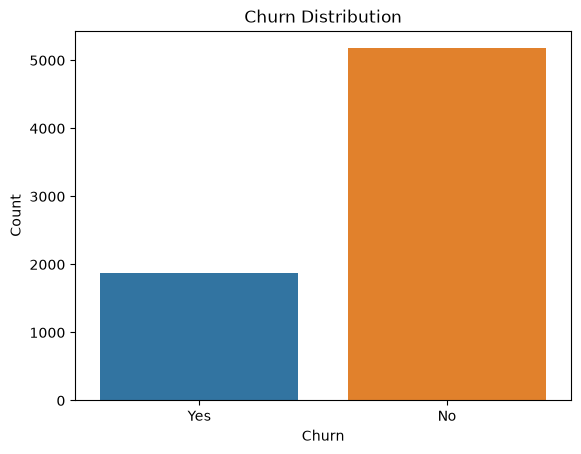

In [12]:
print(df['Churn Label'].value_counts())
sns.countplot(x='Churn Label', data=df, hue='Churn Label')
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

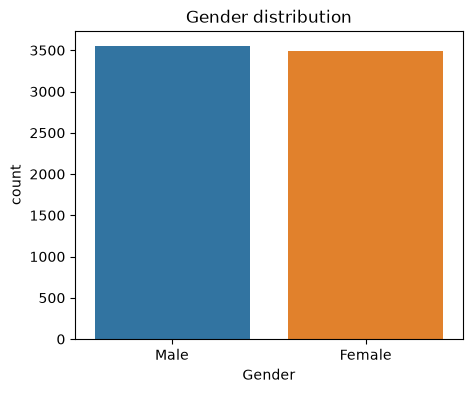

In [13]:
plt.figure(figsize=(5,4))
plt.title('Gender distribution')
sns.countplot(data=df, hue='Gender', x='Gender')
plt.show()

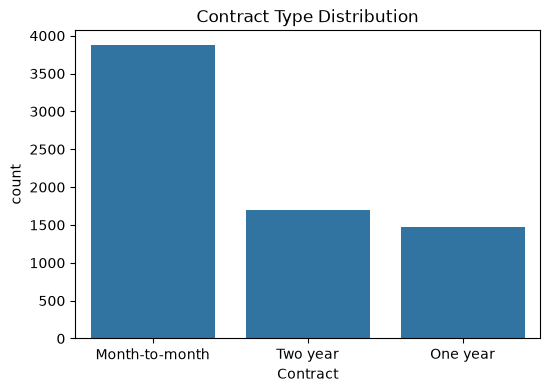

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='Contract', data=df)
plt.title('Contract Type Distribution')
plt.show()

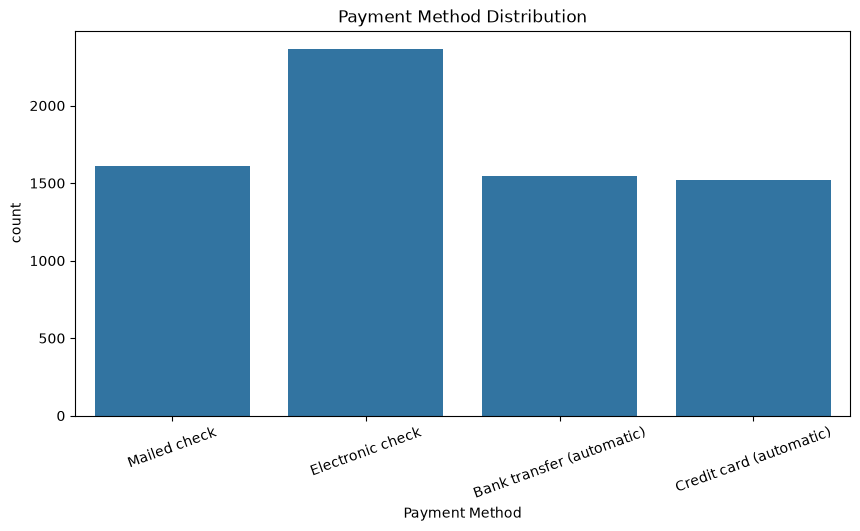

In [15]:
plt.figure(figsize=(10,5))
sns.countplot(x='Payment Method', data=df)
plt.xticks(rotation=20)
plt.title('Payment Method Distribution')
plt.show()

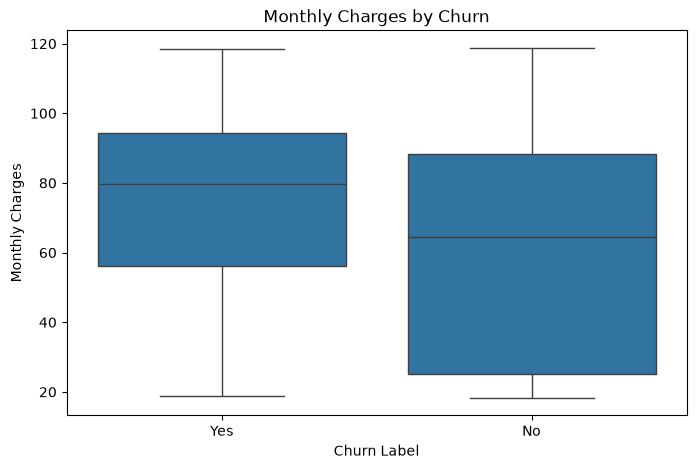

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Churn Label', y='Monthly Charges', data=df)
plt.title('Monthly Charges by Churn')
plt.show()

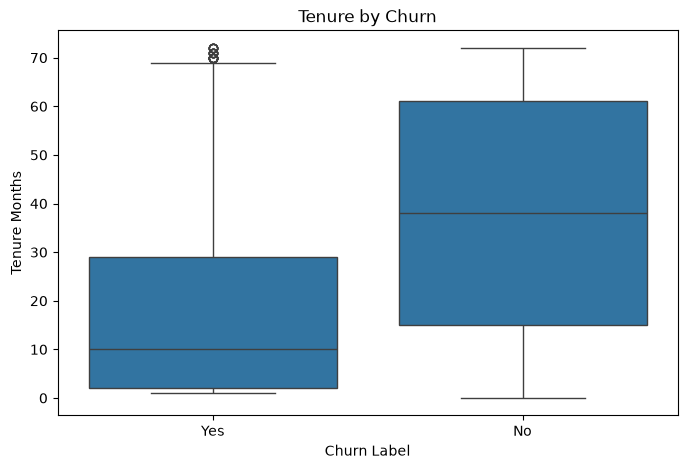

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Churn Label', y='Tenure Months', data=df)
plt.title('Tenure by Churn')
plt.show()

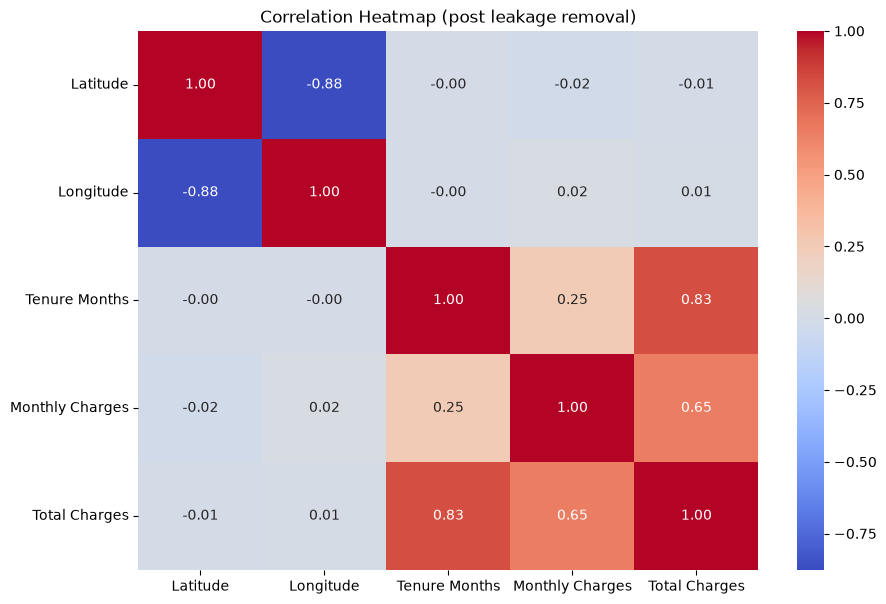

In [18]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10,7))
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Correlation Heatmap (post leakage removal)')
plt.show()

## 8. Feature Encoding
Binary Yes/No (and Gender) columns are mapped directly to 0/1. Columns with more than two categories (e.g. `Contract`, `Payment Method`, `Internet Service`) are one-hot encoded with `pd.get_dummies` instead of `LabelEncoder`, since label-encoding would impose a false ordinal relationship between categories that have no natural order.

In [19]:
binary_map = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}
binary_cols = ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
               'Paperless Billing', 'Churn Label']
for col in binary_cols:
    df[col] = df[col].map(binary_map)

multi_cat_cols = ['Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
                   'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
                   'Contract', 'Payment Method']
df = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

df.head()

,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,...,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964131,-118.272783,1,0,0,0,2,1,1,53.85,...,False,False,False,False,False,False,False,False,False,True
1,34.059281,-118.307420,0,0,0,1,2,1,1,70.70,...,False,False,False,False,False,False,False,False,True,False
2,34.048013,-118.293953,0,0,0,1,8,1,1,99.65,...,False,False,True,False,True,False,False,False,True,False
3,34.062125,-118.315709,0,0,1,1,28,1,1,104.80,...,True,False,True,False,True,False,False,False,True,False
4,34.039224,-118.266293,1,0,0,1,49,1,1,103.70,...,False,False,True,False,True,False,False,False,False,False


## 9. Feature Selection

### Independent Variables

In [20]:
X = df.drop('Churn Label', axis=1)

### Dependent Variable

In [21]:
y = df['Churn Label']

## 10. Train-Test Split

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)
print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (5634, 32)  Test shape: (1409, 32)


## 11. Feature Scaling
Only the genuinely continuous numeric columns are scaled. The one-hot encoded and binary columns are already on a 0/1 scale and don't need it.

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
numeric_cols = ['Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

## 12. Model Training

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=0),
    'Decision Tree': DecisionTreeClassifier(random_state=0),
    'Random Forest': RandomForestClassifier(random_state=0),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)

## 13. Model Evaluation

In [27]:
results = []
for name, pred in predictions.items():
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, pred)
    results.append({'Model': name, 'Accuracy': round(acc, 4), 'ROC-AUC': round(auc, 4)})

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
results_df

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.8176,0.7529
2,Random Forest,0.8041,0.7104
1,Decision Tree,0.7417,0.6662


In [28]:
for name, pred in predictions.items():
    print(f"--- {name} ---")
    print('Confusion Matrix:')
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))
    print()

--- Logistic Regression ---
Confusion Matrix:
[[922 113]
 [144 230]]
              precision    recall  f1-score   support

           0       0.86      0.89      0.88      1035
           1       0.67      0.61      0.64       374

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409


--- Decision Tree ---
Confusion Matrix:
[[856 179]
 [185 189]]
              precision    recall  f1-score   support

           0       0.82      0.83      0.82      1035
           1       0.51      0.51      0.51       374

    accuracy                           0.74      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.74      0.74      1409


--- Random Forest ---
Confusion Matrix:
[[942  93]
 [183 191]]
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0

With leakage columns removed, accuracy drops from the earlier ~99-100% down to a realistic range - this is expected and is a sign the model is now learning genuine churn patterns rather than the answer key.

## 14. Feature Importance (Random Forest)

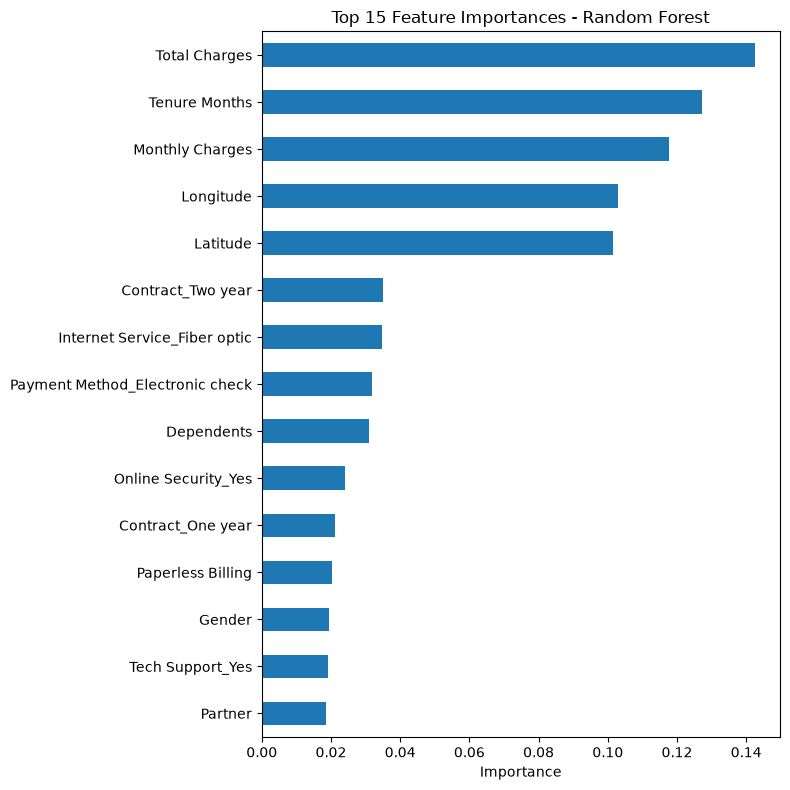

In [29]:
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,8))
importances.head(15).sort_values().plot(kind='barh')
plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 15. Predict a New Customer
Build the new customer as a one-row DataFrame with the **same columns as `X`** (defaulting unspecified one-hot flags to 0), then apply the same scaler before predicting.

In [30]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print('Using best model:', best_model_name)

new_customer = pd.DataFrame([{col: 0 for col in X.columns}])
new_customer['Latitude'] = 34.05
new_customer['Longitude'] = -118.25
new_customer['Gender'] = 1          # Male
new_customer['Senior Citizen'] = 0
new_customer['Partner'] = 0
new_customer['Dependents'] = 0
new_customer['Tenure Months'] = 34
new_customer['Phone Service'] = 1
new_customer['Paperless Billing'] = 1
new_customer['Monthly Charges'] = 70.5
new_customer['Total Charges'] = 2200
# Set any relevant one-hot flags, e.g.:
# new_customer['Contract_One year'] = 1
# new_customer['Internet Service_Fiber optic'] = 1

new_customer[numeric_cols] = scaler.transform(new_customer[numeric_cols])

pred = best_model.predict(new_customer)[0]
prob = best_model.predict_proba(new_customer)[0][1] if hasattr(best_model, 'predict_proba') else None

print('Predicted churn:', 'Yes' if pred == 1 else 'No')
if prob is not None:
    print(f'Predicted churn probability: {prob:.2%}')

Using best model: Logistic Regression
Predicted churn: No
Predicted churn probability: 19.40%
